In [1]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.helper_save_function import save_with_meta
from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.utils import pad_to_length, check_array_lengths
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
current_date = datetime.date.today().strftime("%Y%m%d")
print(current_date)

20261014


In [3]:
df = pd.read_pickle(f"../datasets/Processed/Averages_gChirpFieldsFiltered_20261013.pkl")
df.shape

(3784, 48)

In [4]:
# Determine the set of cond2 values per (date, field) group
group_conditions = df.groupby(["date", "field"])["cond2"].apply(lambda s: set(s.unique()))

# Identify which groups are C1/C2 vs C1/DETANO
c2_groups = group_conditions[group_conditions == {"C1", "C2"}].index
detano_groups = group_conditions[group_conditions == {"C1", "DETANO"}].index

# Build a boolean mask using the (date, field) MultiIndex
df_idx = df.set_index(["date", "field"]).index

df_c2 = df[df_idx.isin(c2_groups)]
df_detano = df[df_idx.isin(detano_groups)]

print(f"C1/C2 groups: {len(c2_groups)}")
print(f"C1/DETANO groups: {len(detano_groups)}")

C1/C2 groups: 5
C1/DETANO groups: 5


# C1 / C2

In [5]:
df_c2.shape

(1858, 48)

In [6]:
df_c1_from_c2 = df_c2[df_c2["cond2"] == "C1"]
df_c2_from_c2 = df_c2[df_c2["cond2"] == "C2"]

print(df_c1_from_c2.shape)
print(df_c2_from_c2.shape)

(929, 48)
(929, 48)


In [7]:
df_c1_cluster_0 = df_c1_from_c2[df_c1_from_c2["cluster_gchirp"] == 0]
df_c2_cluster_0 = df_c2_from_c2[df_c2_from_c2["cluster_gchirp"] == 0]

print(df_c1_cluster_0.shape)
print(df_c2_cluster_0.shape)

print(len(df_c1_cluster_0))
print(len(df_c2_cluster_0))

(168, 48)
(168, 48)
168
168


## C1

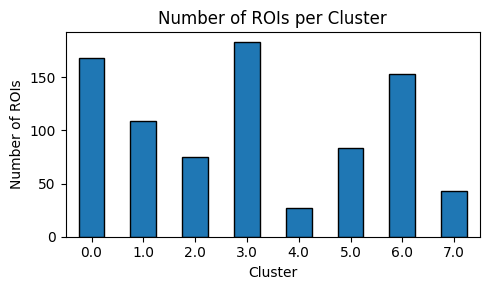

In [8]:
# Count the number of ROIs in each cluster
cluster_counts = df_c1_from_c2["cluster_gchirp"].value_counts().sort_index()

# Plot
plt.figure(figsize=(5, 3))
cluster_counts.plot(kind="bar", edgecolor="black")

plt.xlabel("Cluster")
plt.ylabel("Number of ROIs")
plt.title("Number of ROIs per Cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
cluster_counts = df_c1_from_c2["cluster_gchirp"].value_counts().sort_index()

In [10]:
threshold_chirp = 0.35
threshold_mb = 0.6

gchirp_qi = df_c1_from_c2[df_c1_from_c2["qidx_gChirp"] > threshold_chirp]
lchirp_qi = df_c1_from_c2[df_c1_from_c2["qidx_lChirp"] > threshold_chirp]
mb_qi = df_c1_from_c2[df_c1_from_c2["d_qi_movingbar"] > threshold_mb]

counts_gchirp = gchirp_qi["cluster_gchirp"].value_counts().sort_index()
counts_lchirp = lchirp_qi["cluster_gchirp"].value_counts().sort_index()
counts_mb = mb_qi["cluster_gchirp"].value_counts().sort_index()

In [11]:
counts_comparison = pd.DataFrame({
    "With Cluster Labels": cluster_counts,
    "gChirp_filtered": counts_gchirp,
    "lChirp_filtered": counts_lchirp,
    "mb_filtered": counts_mb})
counts_comparison

,With Cluster Labels,gChirp_filtered,lChirp_filtered,mb_filtered
cluster_gchirp,,,,
0.0,168,168,11.0,151
1.0,109,109,4.0,96
2.0,75,75,NaN,66
3.0,183,183,139.0,167
4.0,27,27,15.0,20
5.0,83,83,19.0,63
6.0,153,153,11.0,133
7.0,43,43,35.0,37


In [12]:
# Boolean masks for each quality criterion (NaN values evaluate to False)
mask_gchirp = df_c1_from_c2["qidx_gChirp"] > threshold_chirp
mask_lchirp = df_c1_from_c2["qidx_lChirp"] > threshold_chirp
mask_mb     = df_c1_from_c2["d_qi_movingbar"] > threshold_mb

# ROI passes if it meets at least one of the three criteria
mask_any = mask_gchirp | mask_lchirp | mask_mb
good_rois = df_c1_from_c2[mask_any]

# Counts per cluster
counts_any = good_rois["cluster_gchirp"].value_counts().sort_index()

counts_comparison = pd.DataFrame({
    "With Cluster Labels": cluster_counts,
    "gChirp_filtered": counts_gchirp,
    "lChirp_filtered": counts_lchirp,
    "mb_filtered": counts_mb,
    "passing_any_qi": counts_any})
    
counts_comparison

,With Cluster Labels,gChirp_filtered,lChirp_filtered,mb_filtered,passing_any_qi
cluster_gchirp,,,,,
0.0,168,168,11.0,151,168
1.0,109,109,4.0,96,109
2.0,75,75,NaN,66,75
3.0,183,183,139.0,167,183
4.0,27,27,15.0,20,27
5.0,83,83,19.0,63,83
6.0,153,153,11.0,133,153
7.0,43,43,35.0,37,43


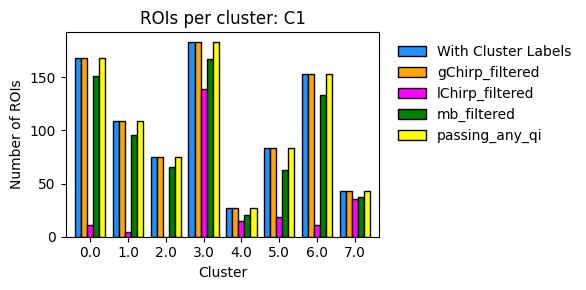

In [13]:
# Plot
ax = counts_comparison.plot(
    kind="bar",
    figsize=(6, 3),
    color=["dodgerblue", "orange", "magenta", "green", "yellow"],
    edgecolor="black",
    width=0.8
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Number of ROIs")
ax.set_title("ROIs per cluster: C1")
ax.tick_params(axis="x", rotation=0)

# Move legend outside the plot, to the right
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

plt.tight_layout()
plt.savefig(f"../plots/qi/C1FromC2_ROIsPerCluster_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

## C2

In [14]:
cluster_counts = df_c2_from_c2["cluster_gchirp"].value_counts().sort_index()

In [15]:
threshold_chirp = 0.35
threshold_mb = 0.6

gchirp_qi = df_c2_from_c2[df_c2_from_c2["qidx_gChirp"] > threshold_chirp]
lchirp_qi = df_c2_from_c2[df_c2_from_c2["qidx_lChirp"] > threshold_chirp]
mb_qi = df_c2_from_c2[df_c2_from_c2["d_qi_movingbar"] > threshold_mb]

counts_gchirp = gchirp_qi["cluster_gchirp"].value_counts().sort_index()
counts_lchirp = lchirp_qi["cluster_gchirp"].value_counts().sort_index()
counts_mb = mb_qi["cluster_gchirp"].value_counts().sort_index()

In [16]:
counts_comparison = pd.DataFrame({
    "With Cluster Labels": cluster_counts,
    "gChirp_filtered": counts_gchirp,
    "lChirp_filtered": counts_lchirp,
    "mb_filtered": counts_mb})
counts_comparison

,With Cluster Labels,gChirp_filtered,lChirp_filtered,mb_filtered
cluster_gchirp,,,,
0.0,168,120,NaN,60
1.0,109,92,NaN,58
2.0,75,54,NaN,30
3.0,183,149,25.0,67
4.0,27,12,1.0,11
5.0,83,56,4.0,28
6.0,153,141,NaN,83
7.0,43,27,14.0,20


In [17]:
# Boolean masks for each quality criterion (NaN values evaluate to False)
mask_gchirp = df_c2_from_c2["qidx_gChirp"] > threshold_chirp
mask_lchirp = df_c2_from_c2["qidx_lChirp"] > threshold_chirp
mask_mb     = df_c2_from_c2["d_qi_movingbar"] > threshold_mb

# ROI passes if it meets at least one of the three criteria
mask_any = mask_gchirp | mask_lchirp | mask_mb
good_rois = df_c2_from_c2[mask_any]

# Counts per cluster
counts_any = good_rois["cluster_gchirp"].value_counts().sort_index()

counts_comparison = pd.DataFrame({
    "With Cluster Labels": cluster_counts,
    "gChirp_filtered": counts_gchirp,
    "lChirp_filtered": counts_lchirp,
    "mb_filtered": counts_mb,
    "passing_any_qi": counts_any})
    
counts_comparison

,With Cluster Labels,gChirp_filtered,lChirp_filtered,mb_filtered,passing_any_qi
cluster_gchirp,,,,,
0.0,168,120,NaN,60,133
1.0,109,92,NaN,58,93
2.0,75,54,NaN,30,56
3.0,183,149,25.0,67,161
4.0,27,12,1.0,11,18
5.0,83,56,4.0,28,62
6.0,153,141,NaN,83,144
7.0,43,27,14.0,20,34


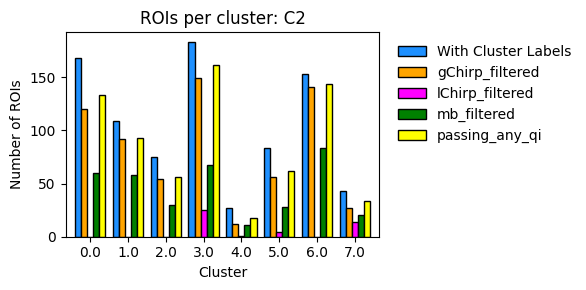

In [18]:
# Plot
ax = counts_comparison.plot(
    kind="bar",
    figsize=(6, 3),
    color=["dodgerblue", "orange", "magenta", "green", "yellow"],
    edgecolor="black",
    width=0.8
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Number of ROIs")
ax.set_title("ROIs per cluster: C2")
ax.tick_params(axis="x", rotation=0)

# Move legend outside the plot, to the right
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

plt.tight_layout()
plt.savefig(f"../plots/qi/C2FromC2_ROIsPerCluster_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

# C1 / DETA/NO

In [19]:
df_detano.shape

(1926, 48)

In [20]:
df_c1_from_no = df_detano[df_detano["cond2"] == "C1"]
df_no_from_no = df_detano[df_detano["cond2"] == "DETANO"]

print(df_c1_from_no.shape)
print(df_no_from_no.shape)

(963, 48)
(963, 48)


## C1

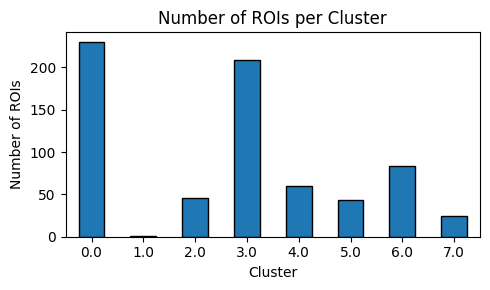

In [21]:
# Count the number of ROIs in each cluster
cluster_counts = df_c1_from_no["cluster_gchirp"].value_counts().sort_index()

# Plot
plt.figure(figsize=(5, 3))
cluster_counts.plot(kind="bar", edgecolor="black")

plt.xlabel("Cluster")
plt.ylabel("Number of ROIs")
plt.title("Number of ROIs per Cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
cluster_counts = df_c1_from_no["cluster_gchirp"].value_counts().sort_index()

In [23]:
threshold_chirp = 0.35
threshold_mb = 0.6

gchirp_qi = df_c1_from_no[df_c1_from_no["qidx_gChirp"] > threshold_chirp]
lchirp_qi = df_c1_from_no[df_c1_from_no["qidx_lChirp"] > threshold_chirp]
mb_qi = df_c1_from_no[df_c1_from_no["d_qi_movingbar"] > threshold_mb]

counts_gchirp = gchirp_qi["cluster_gchirp"].value_counts().sort_index()
counts_lchirp = lchirp_qi["cluster_gchirp"].value_counts().sort_index()
counts_mb = mb_qi["cluster_gchirp"].value_counts().sort_index()

In [24]:
counts_comparison = pd.DataFrame({
    "With Cluster Labels": cluster_counts,
    "gChirp_filtered": counts_gchirp,
    "lChirp_filtered": counts_lchirp,
    "mb_filtered": counts_mb})
counts_comparison

,With Cluster Labels,gChirp_filtered,lChirp_filtered,mb_filtered
cluster_gchirp,,,,
0.0,230,230,4.0,123.0
1.0,1,1,NaN,NaN
2.0,46,46,NaN,8.0
3.0,209,209,183.0,183.0
4.0,60,60,33.0,23.0
5.0,43,43,4.0,12.0
6.0,83,83,12.0,31.0
7.0,24,24,3.0,6.0


In [25]:
# Boolean masks for each quality criterion (NaN values evaluate to False)
mask_gchirp = df_c1_from_no["qidx_gChirp"] > threshold_chirp
mask_lchirp = df_c1_from_no["qidx_lChirp"] > threshold_chirp
mask_mb     = df_c1_from_no["d_qi_movingbar"] > threshold_mb

# ROI passes if it meets at least one of the three criteria
mask_any = mask_gchirp | mask_lchirp | mask_mb
good_rois = df_c1_from_no[mask_any]

# Counts per cluster
counts_any = good_rois["cluster_gchirp"].value_counts().sort_index()

counts_comparison = pd.DataFrame({
    "With Cluster Labels": cluster_counts,
    "gChirp_filtered": counts_gchirp,
    "lChirp_filtered": counts_lchirp,
    "mb_filtered": counts_mb,
    "passing_any_qi": counts_any})
    
counts_comparison

,With Cluster Labels,gChirp_filtered,lChirp_filtered,mb_filtered,passing_any_qi
cluster_gchirp,,,,,
0.0,230,230,4.0,123.0,230
1.0,1,1,NaN,NaN,1
2.0,46,46,NaN,8.0,46
3.0,209,209,183.0,183.0,209
4.0,60,60,33.0,23.0,60
5.0,43,43,4.0,12.0,43
6.0,83,83,12.0,31.0,83
7.0,24,24,3.0,6.0,24


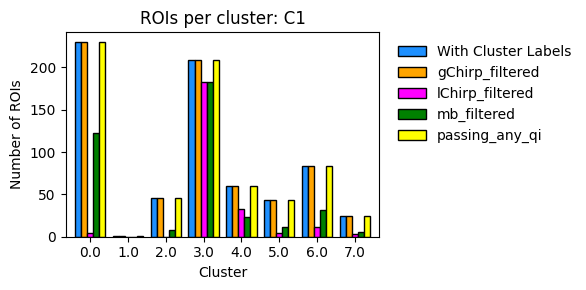

In [26]:
# Plot
ax = counts_comparison.plot(
    kind="bar",
    figsize=(6, 3),
    color=["dodgerblue", "orange", "magenta", "green", "yellow"],
    edgecolor="black",
    width=0.8
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Number of ROIs")
ax.set_title("ROIs per cluster: C1")
ax.tick_params(axis="x", rotation=0)

# Move legend outside the plot, to the right
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

plt.tight_layout()
plt.savefig(f"../plots/qi/C1FromNO_ROIsPerCluster_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

## DETA/NO

In [27]:
cluster_counts = df_no_from_no["cluster_gchirp"].value_counts().sort_index()

In [28]:
threshold_chirp = 0.35
threshold_mb = 0.6

gchirp_qi = df_no_from_no[df_no_from_no["qidx_gChirp"] > threshold_chirp]
lchirp_qi = df_no_from_no[df_no_from_no["qidx_lChirp"] > threshold_chirp]
mb_qi = df_no_from_no[df_no_from_no["d_qi_movingbar"] > threshold_mb]

counts_gchirp = gchirp_qi["cluster_gchirp"].value_counts().sort_index()
counts_lchirp = lchirp_qi["cluster_gchirp"].value_counts().sort_index()
counts_mb = mb_qi["cluster_gchirp"].value_counts().sort_index()

In [29]:
counts_comparison = pd.DataFrame({
    "With Cluster Labels": cluster_counts,
    "gChirp_filtered": counts_gchirp,
    "lChirp_filtered": counts_lchirp,
    "mb_filtered": counts_mb})
counts_comparison

,With Cluster Labels,gChirp_filtered,lChirp_filtered,mb_filtered
cluster_gchirp,,,,
0.0,230,157.0,1.0,114
1.0,1,NaN,NaN,1
2.0,46,35.0,3.0,9
3.0,209,184.0,173.0,196
4.0,60,1.0,25.0,2
5.0,43,22.0,4.0,14
6.0,83,49.0,7.0,24
7.0,24,23.0,5.0,7


In [30]:
# Boolean masks for each quality criterion (NaN values evaluate to False)
mask_gchirp = df_no_from_no["qidx_gChirp"] > threshold_chirp
mask_lchirp = df_no_from_no["qidx_lChirp"] > threshold_chirp
mask_mb     = df_no_from_no["d_qi_movingbar"] > threshold_mb

# ROI passes if it meets at least one of the three criteria
mask_any = mask_gchirp | mask_lchirp | mask_mb
good_rois = df_no_from_no[mask_any]

# Counts per cluster
counts_any = good_rois["cluster_gchirp"].value_counts().sort_index()

counts_comparison = pd.DataFrame({
    "With Cluster Labels": cluster_counts,
    "gChirp_filtered": counts_gchirp,
    "lChirp_filtered": counts_lchirp,
    "mb_filtered": counts_mb,
    "passing_any_qi": counts_any})
    
counts_comparison

,With Cluster Labels,gChirp_filtered,lChirp_filtered,mb_filtered,passing_any_qi
cluster_gchirp,,,,,
0.0,230,157.0,1.0,114,184
1.0,1,NaN,NaN,1,1
2.0,46,35.0,3.0,9,37
3.0,209,184.0,173.0,196,196
4.0,60,1.0,25.0,2,28
5.0,43,22.0,4.0,14,27
6.0,83,49.0,7.0,24,59
7.0,24,23.0,5.0,7,23


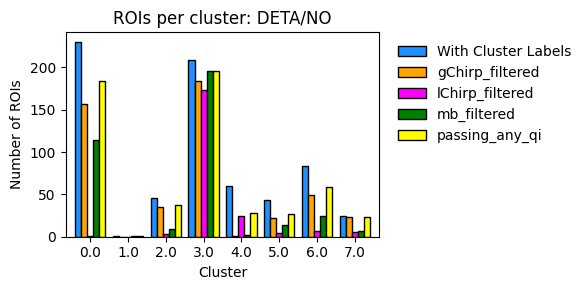

In [31]:
# Plot
ax = counts_comparison.plot(
    kind="bar",
    figsize=(6, 3),
    color=["dodgerblue", "orange", "magenta", "green", "yellow"],
    edgecolor="black",
    width=0.8
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Number of ROIs")
ax.set_title("ROIs per cluster: DETA/NO")
ax.tick_params(axis="x", rotation=0)

# Move legend outside the plot, to the right
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

plt.tight_layout()
plt.savefig(f"../plots/qi/NOFromNO_ROIsPerCluster_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()